# PHY Sweep Evaluation — s1 / s2 / s3

This notebook evaluates a (μ, W, MCS) PHY sweep across three scenarios:

| Scenario | Variable    | Conditions             |
|----------|-------------|------------------------|
| s1       | group size  | nrx02..nrx20           |
| s2       | inter-distance (m) | ivd010..ivd150 |
| s3       | speed (km/h)| spd030..spd200         |

Inputs:
- `tmp/_summary.csv` (local) — covers s1 fully, partial s2.
- `ease_summary.csv` (project root, copied from remote) — covers s2 fully, partial s3.

Sections 4 and 5 use raw `*.db.gz` from `tmp/` (s1-only) via the helper
`per_rx_prr.py`. To run section 4/5 on the remote machine, copy the helper
and the SUMO directory there and run:

```
python3 scratch_overlay/adaptive-phy-eval/scripts/per_rx_prr.py \
    --tmp <remote_tmp> --scen s1 --out per_rx_s1.csv
```

In [1]:
from pathlib import Path
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams["figure.dpi"] = 110

REPO = Path.cwd()
while REPO != REPO.parent and not (REPO / "ns-3-dev").exists():
    REPO = REPO.parent
print("repo:", REPO)

LOCAL_SUMMARY  = REPO / "tmp" / "_summary.csv"
REMOTE_SUMMARY = REPO / "ease_summary.csv"
PER_RX_CSV     = REPO / "tmp" / "per_rx_s1.csv"
PER_RX_PAIR    = REPO / "tmp" / "per_rx_s1.pair.csv"
HELPER_SCRIPT  = REPO / "scratch_overlay" / "adaptive-phy-eval" / "scripts" / "per_rx_prr.py"
FLOW_LABELS = ["prr_group", "prr_cam", "prr_vid", "prr_bg"]
FLOW_COLORS = {"prr_group": "k", "prr_cam": "tab:blue",
               "prr_vid": "tab:orange", "prr_bg": "tab:green"}

repo: /Users/hadih/Documents/groupcast-adaptation-ns3


## 1. Load & merge summary CSVs

In [2]:
def load_summary(p):
    if not p.exists():
        print(f"  missing: {p}")
        return None
    df = pd.read_csv(p)
    df["source"] = p.name
    return df

local = load_summary(LOCAL_SUMMARY)
remote = load_summary(REMOTE_SUMMARY)
df = pd.concat([d for d in (local, remote) if d is not None], ignore_index=True)
# Prefer local row when stems collide
df = df.sort_values("source", ascending=True).drop_duplicates("stem", keep="first")
print(f"loaded {len(df)} rows; scenarios:")
print(df.groupby(["scen", "cond"]).size().unstack(fill_value=0))

loaded 6778 rows; scenarios:
cond  ivd010m  ivd020m  ivd050m  ivd100m  ivd150m  nrx02  nrx04  nrx08  nrx12  \
scen                                                                            
s1          0        0        0        0        0    560    560    560    507   
s2        560      560      560      560      560      0      0      0      0   
s3          0        0        0        0        0      0      0      0      0   

cond  nrx16  nrx20  spd030kmh  spd060kmh  spd100kmh  
scen                                                 
s1      302    141          0          0          0  
s2        0      0          0          0          0  
s3        0      0        560        461        327  


In [3]:
# Numeric scenario variable per row
def cond_to_var(scen, cond):
    if scen == "s1":
        return int(cond[3:])               # nrx08 -> 8
    if scen == "s2":
        return int(cond[3:].rstrip("m"))   # ivd050m -> 50
    if scen == "s3":
        return int(cond[3:].rstrip("kmh")) # spd060kmh -> 60
    return None

df["scen_var"] = df.apply(lambda r: cond_to_var(r["scen"], r["cond"]), axis=1)
SCEN_VAR_LABEL = {"s1": "n_ues", "s2": "inter-distance [m]", "s3": "speed [km/h]"}

# Aggregated KPIs over seeds → (scen, cond, mu, w, mcs)
agg_keys = ["scen", "cond", "scen_var", "mu", "w", "mcs"]
metrics = ["prr_group", "prr_cam", "prr_vid", "prr_bg",
           "coll_rate", "pssch_bler", "sinr_mean_db"]
agg = (df.groupby(agg_keys, dropna=False)[metrics]
         .agg(["mean", "std", "count"]).reset_index())
agg.columns = ["_".join([c for c in col if c]).rstrip("_") for col in agg.columns]
print(agg.shape)
agg.head(3)

(1365, 27)


,scen,cond,scen_var,mu,w,mcs,prr_group_mean,prr_group_std,prr_group_count,prr_cam_mean,...,prr_bg_count,coll_rate_mean,coll_rate_std,coll_rate_count,pssch_bler_mean,pssch_bler_std,pssch_bler_count,sinr_mean_db_mean,sinr_mean_db_std,sinr_mean_db_count
0,s1,nrx02,2,1,25,0,0.000000,0.000000,5,0.009462,...,5,0.781027,0.015056,5,0.0,0.0,5,43.848307,0.511616,5
1,s1,nrx02,2,1,25,3,0.002169,0.001534,5,0.529601,...,5,0.420181,0.010229,5,0.0,0.0,5,42.226071,0.491312,5
2,s1,nrx02,2,1,25,5,0.013015,0.002169,5,0.539495,...,5,0.412240,0.013851,5,0.0,0.0,5,42.965847,0.503267,5


## 2. PHY sensitivity per scenario

For each scenario, plot mean PRR vs each PHY axis (μ, W, MCS), aggregating
over seeds and over the other two PHY axes.

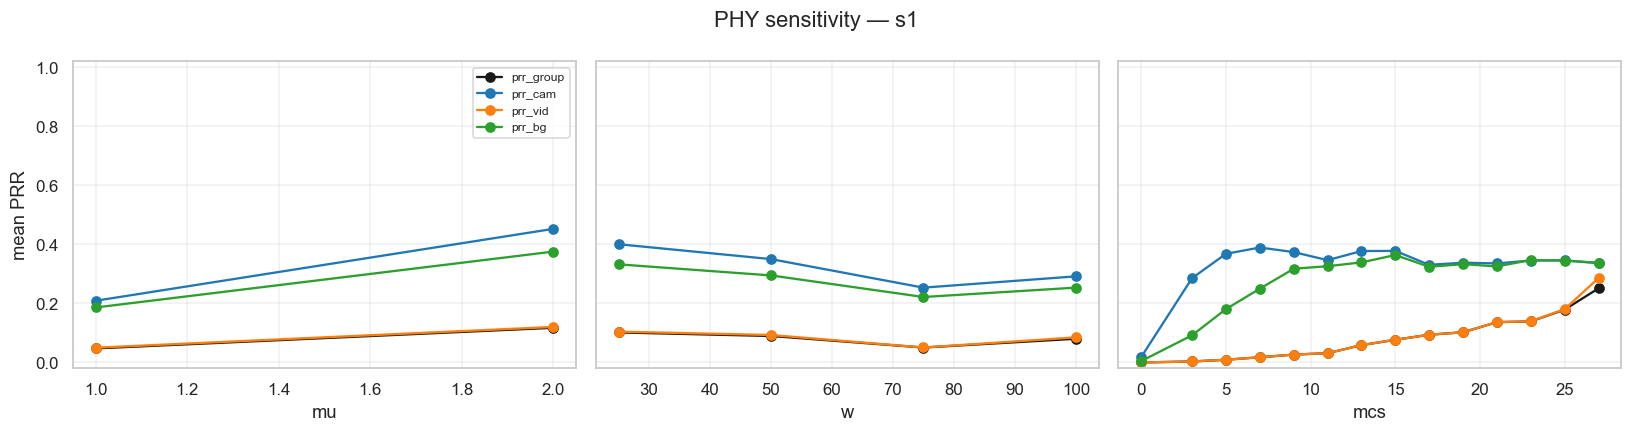

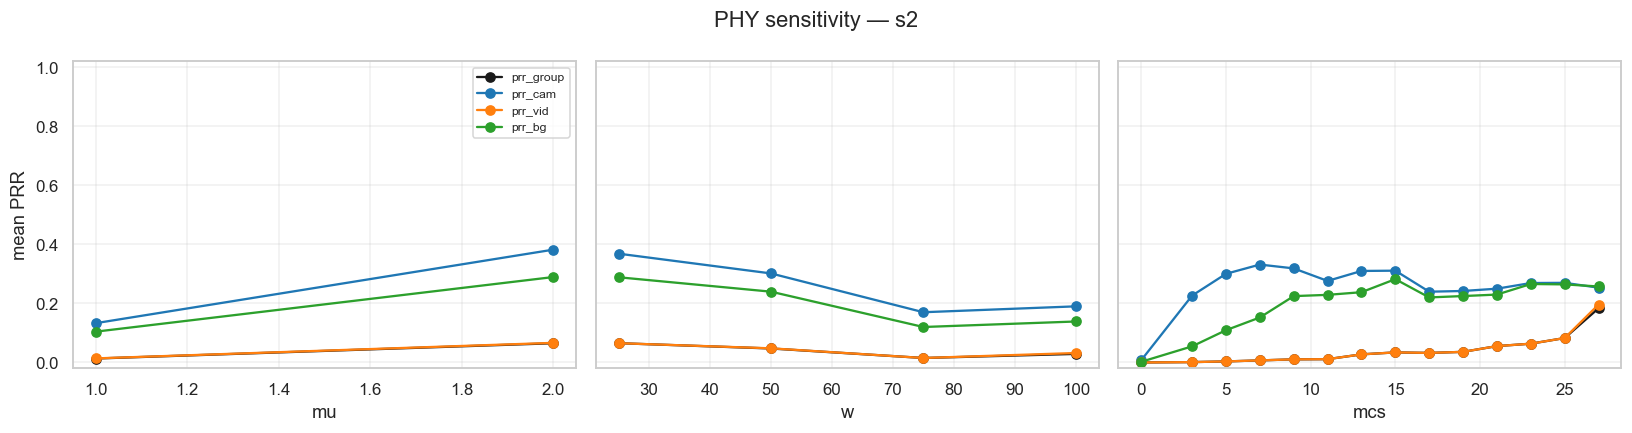

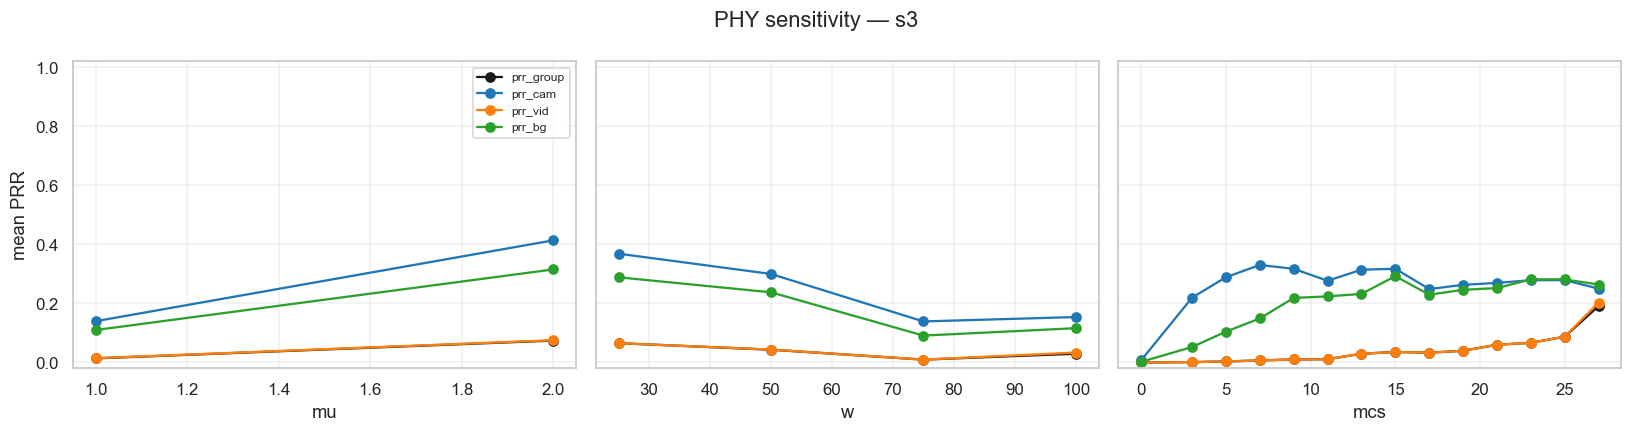

In [4]:
def phy_sensitivity_plot(agg, scen):
    sub = agg[agg["scen"] == scen]
    if sub.empty:
        print(f"no data for {scen}")
        return
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for ax, axis in zip(axes, ["mu", "w", "mcs"]):
        # mean over the other PHY axes and over conds (per seed already averaged)
        g = sub.groupby(axis)[[f"{m}_mean" for m in FLOW_LABELS]].mean()
        for m in FLOW_LABELS:
            ax.plot(g.index, g[f"{m}_mean"], "o-", label=m, color=FLOW_COLORS[m])
        ax.set_xlabel(axis)
        ax.set_ylim(-0.02, 1.02)
        ax.grid(True, alpha=0.3)
    axes[0].set_ylabel("mean PRR")
    axes[0].legend(loc="best", fontsize=8)
    fig.suptitle(f"PHY sensitivity — {scen}")
    fig.tight_layout()
    plt.show()

for s in ("s1", "s2", "s3"):
    phy_sensitivity_plot(agg, s)

## 3. Optimal (μ, W, MCS) vs scenario variable

For each cond, pick the (μ, W, MCS) maximising mean group PRR over seeds.
Compare per-cond optimum to the globally best fixed triple (across that
scenario) — the gap is the price of non-adaptive PHY.

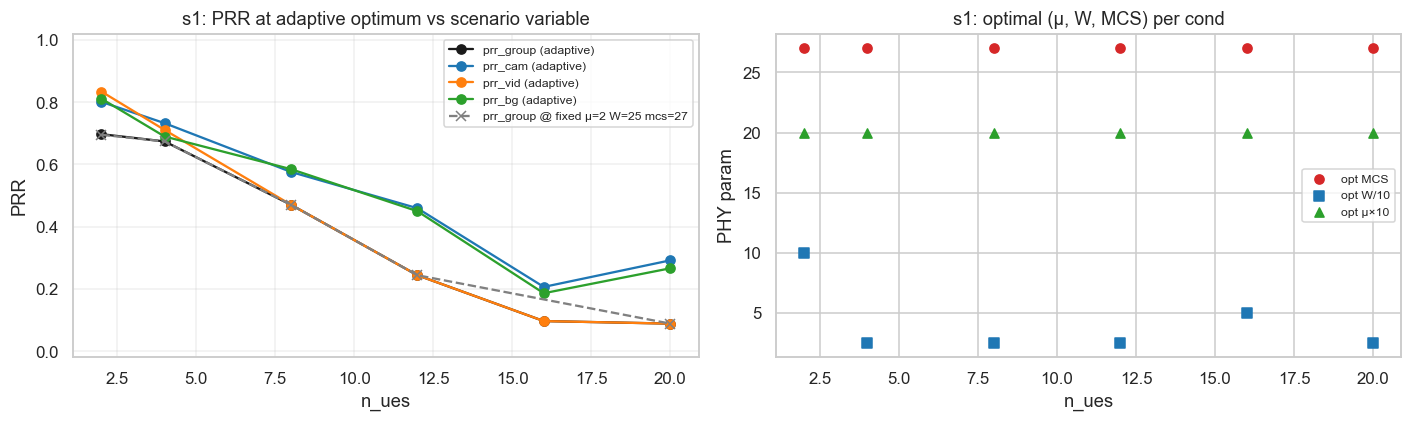


[s1] adaptive-optimum table:
 scen_var  cond  mu   w  mcs  prr_group_mean  prr_cam_mean  prr_vid_mean  prr_bg_mean
        2 nrx02   2 100   27           0.697         0.801         0.834        0.811
        4 nrx04   2  25   27           0.674         0.733         0.711        0.690
        8 nrx08   2  25   27           0.470         0.576         0.470        0.585
       12 nrx12   2  25   27           0.244         0.459         0.244        0.450
       16 nrx16   2  50   27           0.097         0.206         0.097        0.186
       20 nrx20   2  25   27           0.089         0.292         0.089        0.266

[s1] best fixed triple: μ=2 W=25 mcs=27


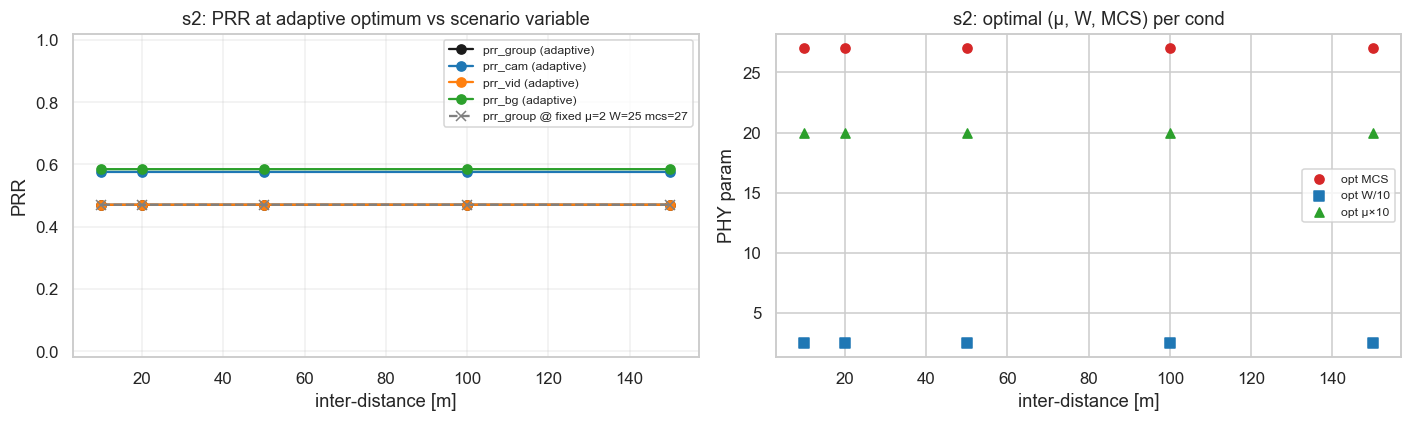


[s2] adaptive-optimum table:
 scen_var    cond  mu  w  mcs  prr_group_mean  prr_cam_mean  prr_vid_mean  prr_bg_mean
       10 ivd010m   2 25   27           0.470         0.576         0.470        0.585
       20 ivd020m   2 25   27           0.470         0.576         0.470        0.585
       50 ivd050m   2 25   27           0.470         0.576         0.470        0.585
      100 ivd100m   2 25   27           0.470         0.576         0.470        0.585
      150 ivd150m   2 25   27           0.470         0.576         0.470        0.585

[s2] best fixed triple: μ=2 W=25 mcs=27


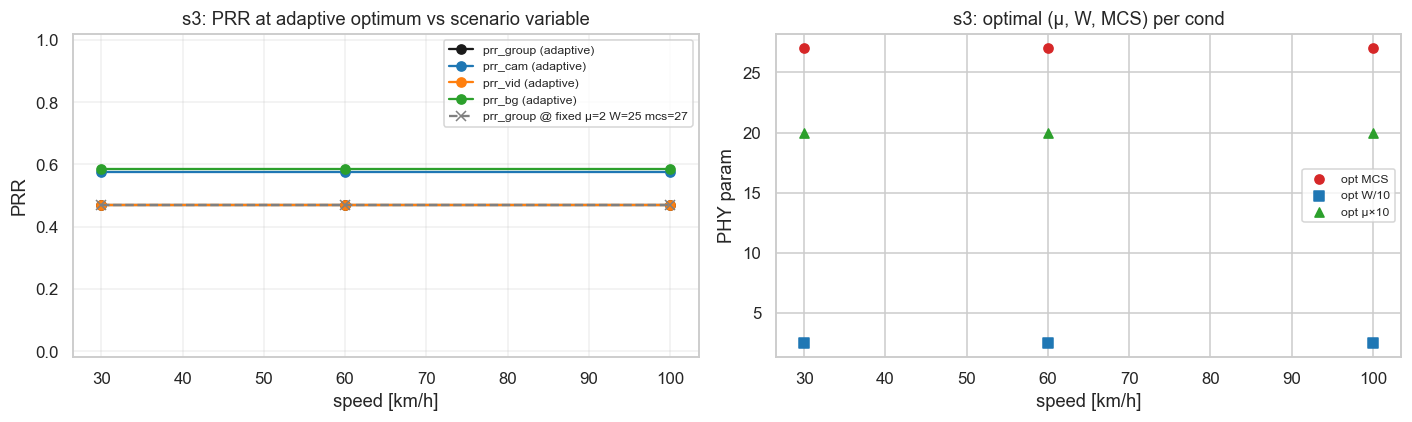


[s3] adaptive-optimum table:
 scen_var      cond  mu  w  mcs  prr_group_mean  prr_cam_mean  prr_vid_mean  prr_bg_mean
       30 spd030kmh   2 25   27           0.470         0.576         0.470        0.585
       60 spd060kmh   2 25   27           0.470         0.576         0.470        0.585
      100 spd100kmh   2 25   27           0.470         0.576         0.470        0.585

[s3] best fixed triple: μ=2 W=25 mcs=27


In [5]:
def optimal_table(agg, scen):
    sub = agg[(agg["scen"] == scen) & agg["prr_group_mean"].notna()].copy()
    if sub.empty:
        return None
    idx = sub.groupby(["scen_var", "cond"])["prr_group_mean"].idxmax()
    opt = sub.loc[idx].sort_values("scen_var").reset_index(drop=True)
    # Global fixed best triple: argmax of mean PRR across all conds
    glob = (sub.groupby(["mu", "w", "mcs"])["prr_group_mean"].mean()
              .reset_index().sort_values("prr_group_mean", ascending=False))
    best_triple = tuple(glob.iloc[0][["mu", "w", "mcs"]].astype(int))
    fixed = sub[(sub["mu"] == best_triple[0]) & (sub["w"] == best_triple[1]) &
                (sub["mcs"] == best_triple[2])].sort_values("scen_var")
    return opt, fixed, best_triple


def optimal_plot(agg, scen):
    res = optimal_table(agg, scen)
    if res is None:
        print(f"no data for {scen}")
        return
    opt, fixed, best_triple = res
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    ax = axes[0]
    for m in FLOW_LABELS:
        ax.plot(opt["scen_var"], opt[f"{m}_mean"], "o-",
                label=f"{m} (adaptive)", color=FLOW_COLORS[m])
    ax.plot(fixed["scen_var"], fixed["prr_group_mean"], "x--",
            color="gray", label=f"prr_group @ fixed μ={best_triple[0]} "
                                f"W={best_triple[1]} mcs={best_triple[2]}")
    ax.set_xlabel(SCEN_VAR_LABEL[scen])
    ax.set_ylabel("PRR")
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_title(f"{scen}: PRR at adaptive optimum vs scenario variable")

    ax = axes[1]
    ax.scatter(opt["scen_var"], opt["mcs"], c="tab:red",  label="opt MCS")
    ax.scatter(opt["scen_var"], opt["w"]/10, c="tab:blue", marker="s", label="opt W/10")
    ax.scatter(opt["scen_var"], opt["mu"]*10, c="tab:green", marker="^", label="opt μ×10")
    ax.set_xlabel(SCEN_VAR_LABEL[scen])
    ax.set_ylabel("PHY param")
    ax.legend(fontsize=8)
    ax.set_title(f"{scen}: optimal (μ, W, MCS) per cond")
    fig.tight_layout()
    plt.show()

    print(f"\n[{scen}] adaptive-optimum table:")
    cols = ["scen_var", "cond", "mu", "w", "mcs",
            "prr_group_mean", "prr_cam_mean", "prr_vid_mean", "prr_bg_mean"]
    print(opt[cols].to_string(index=False, float_format="%.3f"))
    print(f"\n[{scen}] best fixed triple: μ={best_triple[0]} W={best_triple[1]} "
          f"mcs={best_triple[2]}")


for s in ("s1", "s2", "s3"):
    optimal_plot(agg, s)

## 4. (s1) Per-rx PRR vs distance

Uses `per_rx_prr.py` to compute per-receiver PRR (aggregate over senders)
and pairwise (tx,rx) PRR from the gzipped sqlite DBs in `tmp/`.

In [6]:
if not PER_RX_CSV.exists():
    print("Running per_rx_prr.py for s1 ...")
    subprocess.run([sys.executable, str(HELPER_SCRIPT),
                    "--tmp", str(REPO / "tmp"),
                    "--scen", "s1",
                    "--out", str(PER_RX_CSV)], check=True)
prr_rx = pd.read_csv(PER_RX_CSV)
prr_pair = pd.read_csv(PER_RX_PAIR)
print("agg rows:", len(prr_rx), "pair rows:", len(prr_pair))
prr_rx.head(3)

agg rows: 64728 pair rows: 696552


,stem,scen,cond,n_ues,mu,w,mcs,seed,rx_node,distance_m,flow,prr_rx,rx_count,expected
0,s1_nrx02_mu1_w100_mcs0_seed1,s1,nrx02,2,1,100,0,1,0,0.0,cam,0.007819,9,1151
1,s1_nrx02_mu1_w100_mcs0_seed1,s1,nrx02,2,1,100,0,1,0,0.0,vid,0.000000,0,461
2,s1_nrx02_mu1_w100_mcs0_seed1,s1,nrx02,2,1,100,0,1,0,0.0,bg,0.004329,1,231


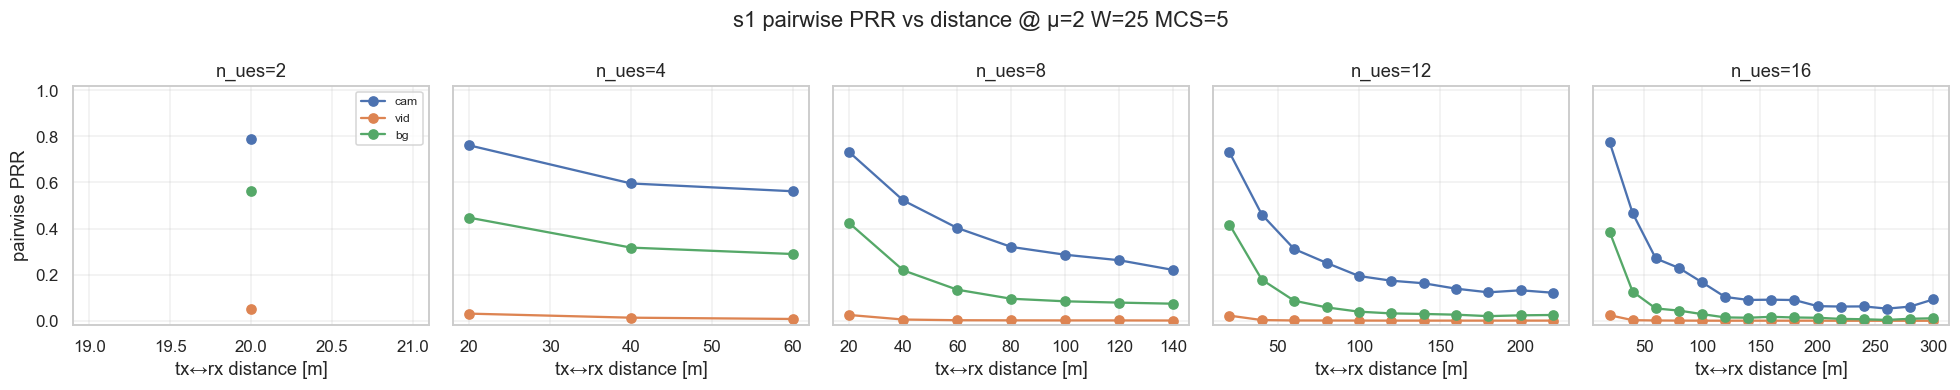

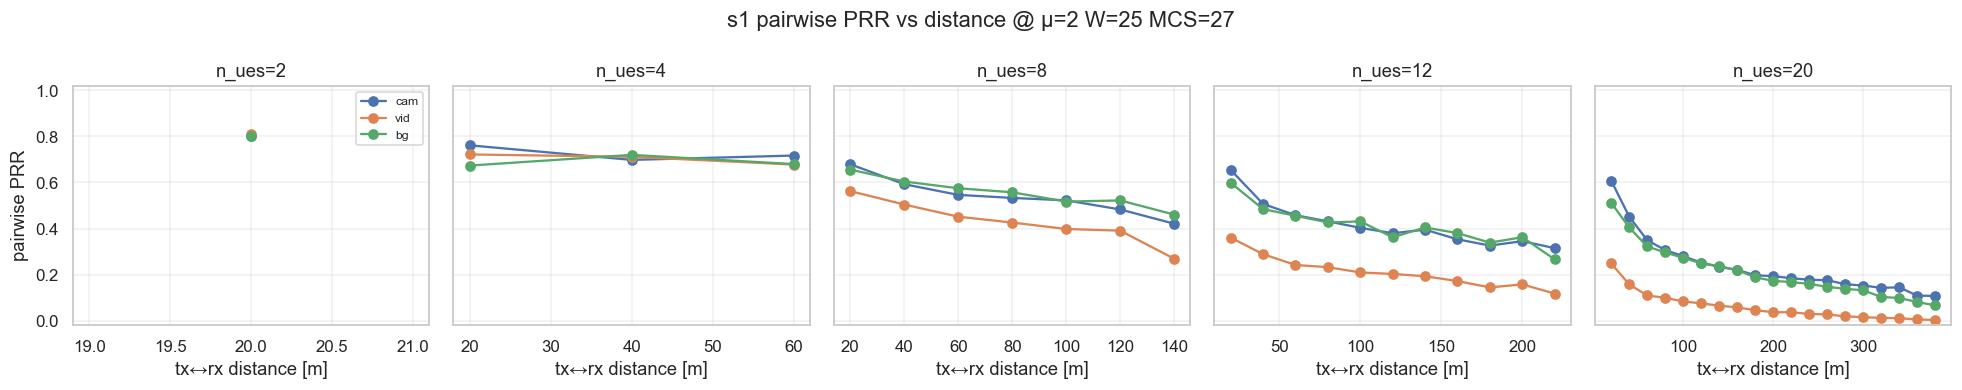

In [19]:
# Pairwise PRR vs distance, per flow, faceted by group size at one PHY
def pair_prr_vs_distance(prr_pair, mu=1, w=100, mcs=5):
    sub = prr_pair[(prr_pair["mu"] == mu) & (prr_pair["w"] == w) &
                   (prr_pair["mcs"] == mcs)].copy()
    if sub.empty:
        print("no data")
        return
    g = (sub.groupby(["n_ues", "distance_m", "flow"])["prr_pair"]
            .mean().reset_index())
    sizes = sorted(g["n_ues"].unique())
    fig, axes = plt.subplots(1, len(sizes), figsize=(3.6*len(sizes), 3.6),
                             sharey=True)
    if len(sizes) == 1:
        axes = [axes]
    for ax, n in zip(axes, sizes):
        gi = g[g["n_ues"] == n]
        for flow in ("cam", "vid", "bg"):
            gf = gi[gi["flow"] == flow]
            ax.plot(gf["distance_m"], gf["prr_pair"], "o-", label=flow)
        ax.set_title(f"n_ues={n}")
        ax.set_xlabel("tx↔rx distance [m]")
        ax.set_ylim(-0.02, 1.02)
        ax.grid(True, alpha=0.3)
    axes[0].set_ylabel("pairwise PRR")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"s1 pairwise PRR vs distance @ μ={mu} W={w} MCS={mcs}")
    fig.tight_layout()
    plt.show()

for mcs in (5, 27):
    pair_prr_vs_distance(prr_pair, mu=2, w=25, mcs=mcs)

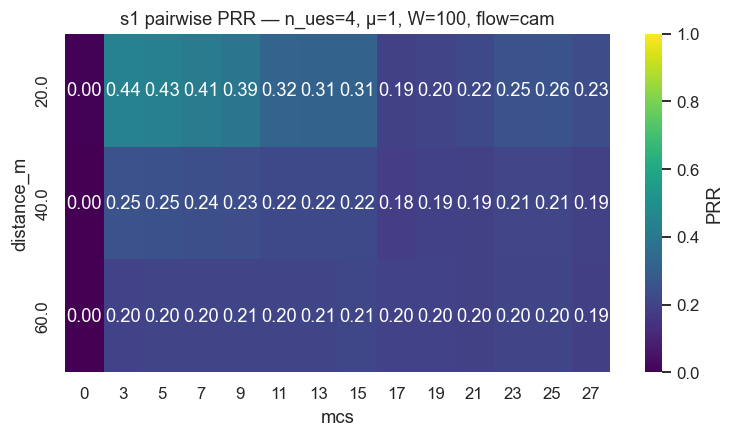

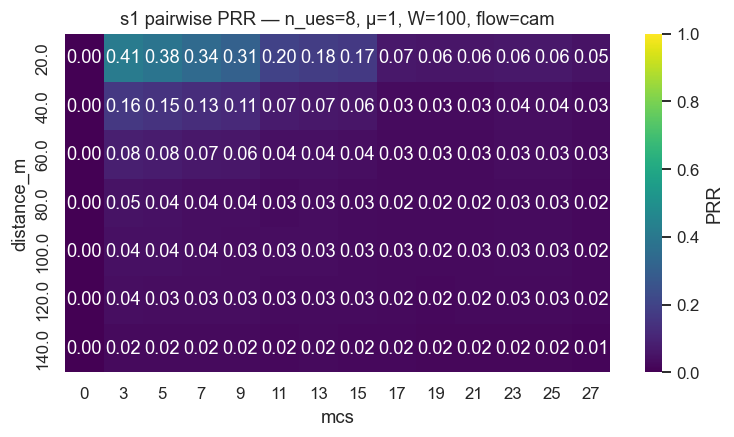

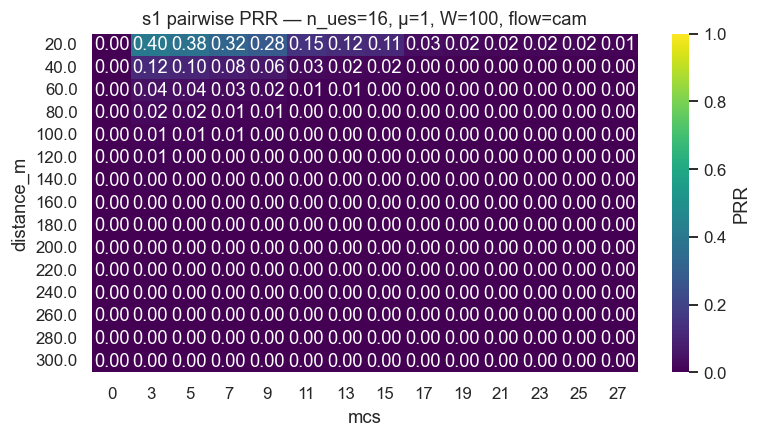

In [8]:
# Heatmap: PRR over (distance, MCS) at fixed (μ, W, n_ues) — flow=cam
def prr_distance_mcs_heatmap(prr_pair, n_ues=8, mu=1, w=100, flow="cam"):
    sub = prr_pair[(prr_pair["n_ues"] == n_ues) & (prr_pair["mu"] == mu) &
                   (prr_pair["w"] == w) & (prr_pair["flow"] == flow)]
    if sub.empty:
        print("no data")
        return
    pv = (sub.groupby(["distance_m", "mcs"])["prr_pair"].mean()
            .unstack("mcs"))
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="viridis",
                vmin=0, vmax=1, ax=ax, cbar_kws={"label": "PRR"})
    ax.set_title(f"s1 pairwise PRR — n_ues={n_ues}, μ={mu}, W={w}, flow={flow}")
    plt.show()

for n in (4, 8, 16):
    prr_distance_mcs_heatmap(prr_pair, n_ues=n, mu=1, w=100, flow="cam")

## 5. (s1) Best MCS per receiver vs distance

For each (n_ues, μ, W, distance), pick the MCS that maximises mean PRR.
This is the "what MCS should rx_k pick" view.

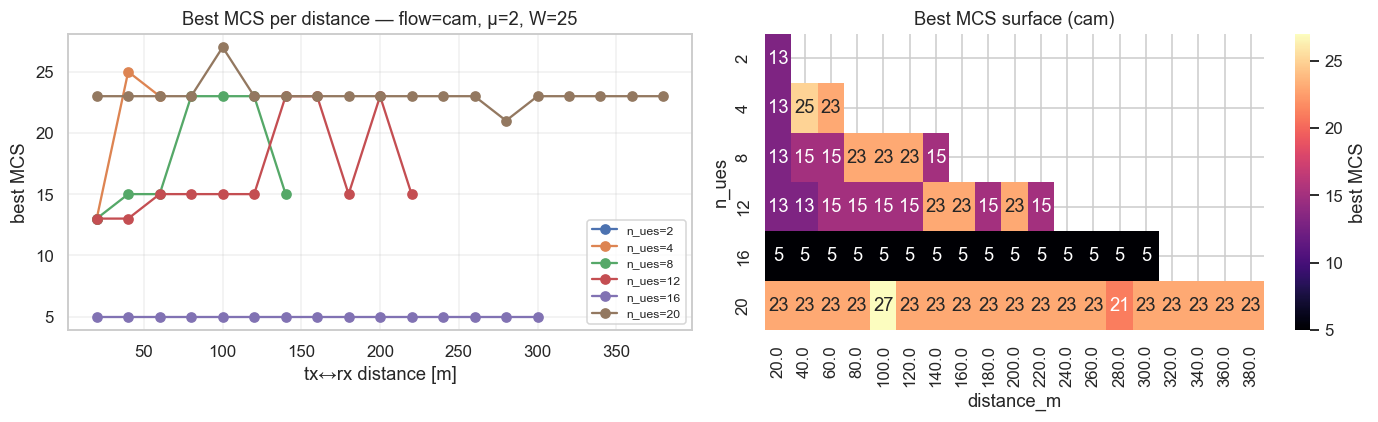

 n_ues  distance_m  mcs  prr_pair
     2        20.0   13  0.802980
     4        20.0   13  0.781403
     4        40.0   25  0.702509
     4        60.0   23  0.728020
     8        20.0   13  0.753135
     8        40.0   15  0.640530
     8        60.0   15  0.575740
     8        80.0   23  0.553745
     8       100.0   23  0.541928
     8       120.0   23  0.500594
     8       140.0   15  0.444033
    12        20.0   13  0.754280
    12        40.0   13  0.586700
    12        60.0   15  0.497743
    12        80.0   15  0.453433
    12       100.0   15  0.417295
    12       120.0   15  0.389464
    12       140.0   23  0.401495
    12       160.0   23  0.366985
    12       180.0   15  0.361159
    12       200.0   23  0.362881
    12       220.0   15  0.347708
    16        20.0    5  0.775871
    16        40.0    5  0.466549
    16        60.0    5  0.270374
    16        80.0    5  0.229194
    16       100.0    5  0.166897
    16       120.0    5  0.103289
    16       1

In [17]:
def best_mcs_per_distance(prr_pair, mu=1, w=100, flow="cam"):
    sub = prr_pair[(prr_pair["mu"] == mu) & (prr_pair["w"] == w) &
                   (prr_pair["flow"] == flow)]
    if sub.empty:
        print("no data")
        return None
    g = (sub.groupby(["n_ues", "distance_m", "mcs"])["prr_pair"]
            .mean().reset_index())
    idx = g.groupby(["n_ues", "distance_m"])["prr_pair"].idxmax()
    best = g.loc[idx].sort_values(["n_ues", "distance_m"]).reset_index(drop=True)
    return best

best = best_mcs_per_distance(prr_pair, mu=2, w=25, flow="cam")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for n in sorted(best["n_ues"].unique()):
    bi = best[best["n_ues"] == n]
    ax.plot(bi["distance_m"], bi["mcs"], "o-", label=f"n_ues={n}")
ax.set_xlabel("tx↔rx distance [m]")
ax.set_ylabel("best MCS")
ax.set_title("Best MCS per distance — flow=cam, μ=2, W=25")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

# 2D heatmap of best MCS over (n_ues, distance)
ax = axes[1]
pv = best.pivot_table(index="n_ues", columns="distance_m", values="mcs")
sns.heatmap(pv, annot=True, fmt=".0f", cmap="magma", ax=ax,
            cbar_kws={"label": "best MCS"})
ax.set_title("Best MCS surface (cam)")
plt.tight_layout()
plt.show()
print(best.to_string(index=False))

## 6. PHY trade-off heatmaps (per scenario)

Mean group PRR over (W, MCS) at each μ — shows the robustness/capacity saddle.

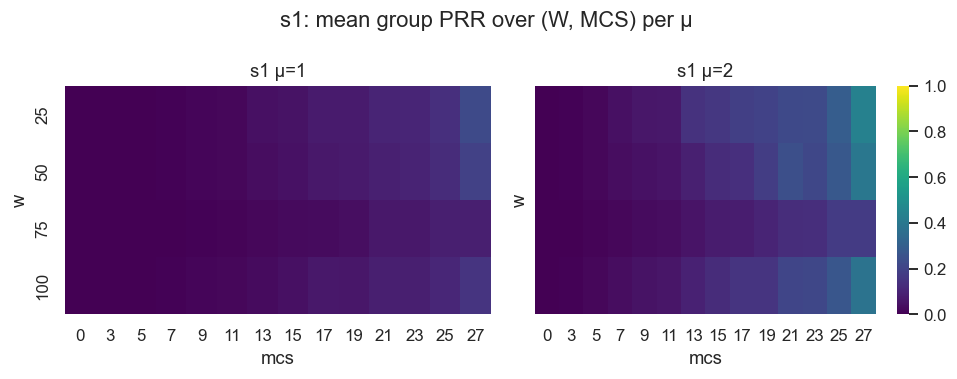

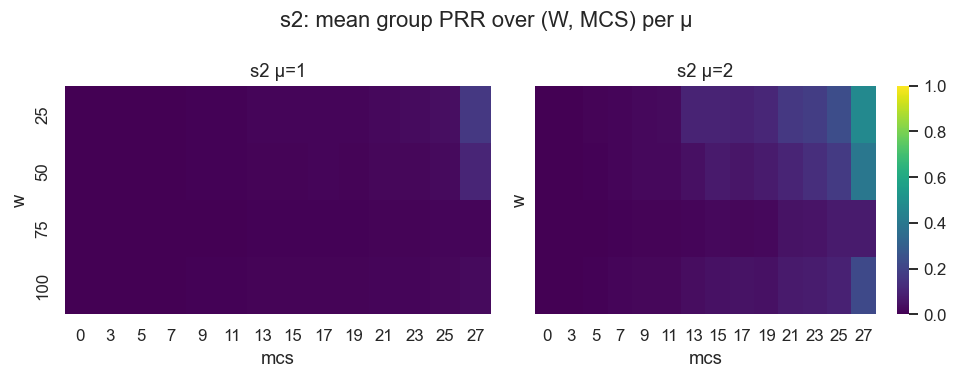

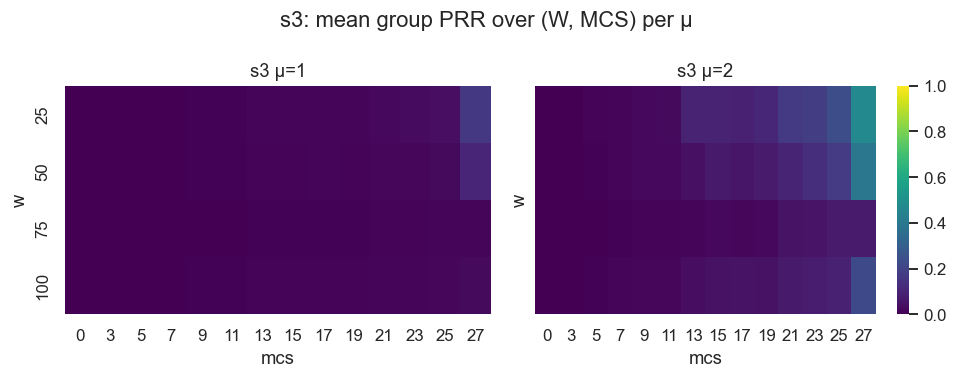

In [10]:
def phy_heatmaps(agg, scen):
    sub = agg[agg["scen"] == scen]
    if sub.empty:
        return
    mus = sorted(sub["mu"].unique())
    fig, axes = plt.subplots(1, len(mus), figsize=(4.5*len(mus), 3.5),
                             sharey=True)
    if len(mus) == 1:
        axes = [axes]
    for ax, mu in zip(axes, mus):
        pv = (sub[sub["mu"] == mu]
              .groupby(["w", "mcs"])["prr_group_mean"].mean()
              .unstack("mcs"))
        sns.heatmap(pv, annot=False, cmap="viridis", vmin=0, vmax=1, ax=ax,
                    cbar=(ax is axes[-1]))
        ax.set_title(f"{scen} μ={mu}")
    fig.suptitle(f"{scen}: mean group PRR over (W, MCS) per μ")
    fig.tight_layout()
    plt.show()

for s in ("s1", "s2", "s3"):
    phy_heatmaps(agg, s)

## 7. Collision vs BLER decomposition

Helps see whether each scenario is collision-limited or link-limited.

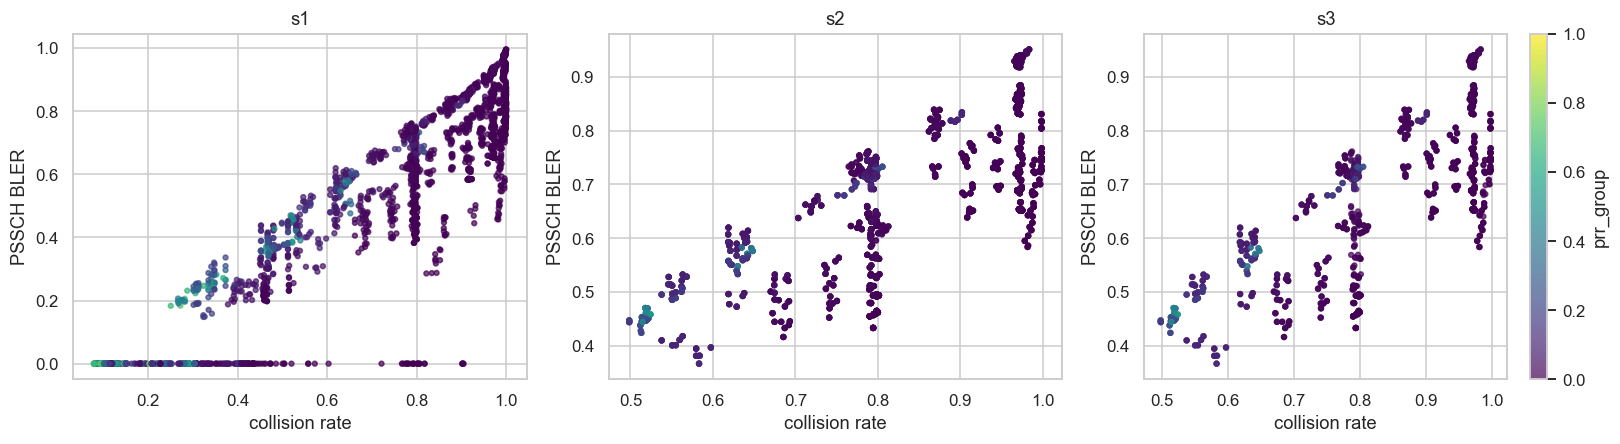

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, scen in zip(axes, ("s1", "s2", "s3")):
    sub = df[df["scen"] == scen]
    sc = ax.scatter(sub["coll_rate"], sub["pssch_bler"],
                    c=sub["prr_group"], cmap="viridis",
                    vmin=0, vmax=1, s=10, alpha=0.7)
    ax.set_title(scen)
    ax.set_xlabel("collision rate")
    ax.set_ylabel("PSSCH BLER")
plt.colorbar(sc, ax=axes[-1], label="prr_group")
plt.tight_layout()
plt.show()

## 8. SINR → PRR curves

Empirical "rate curves" derived from the sweep. Bin runs by mean SINR per
MCS and plot mean group PRR.

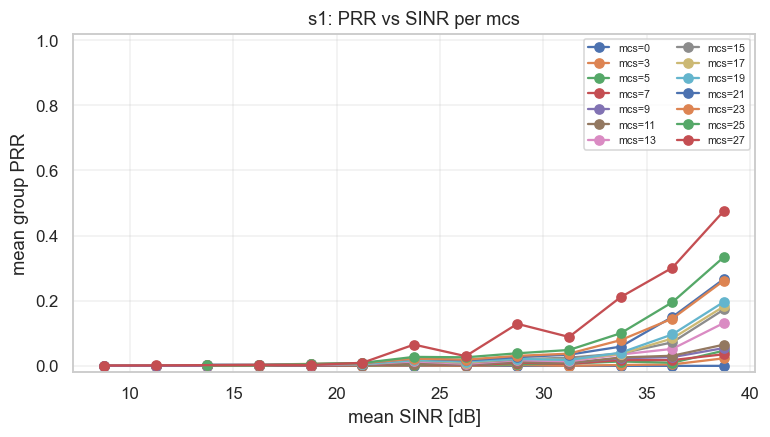

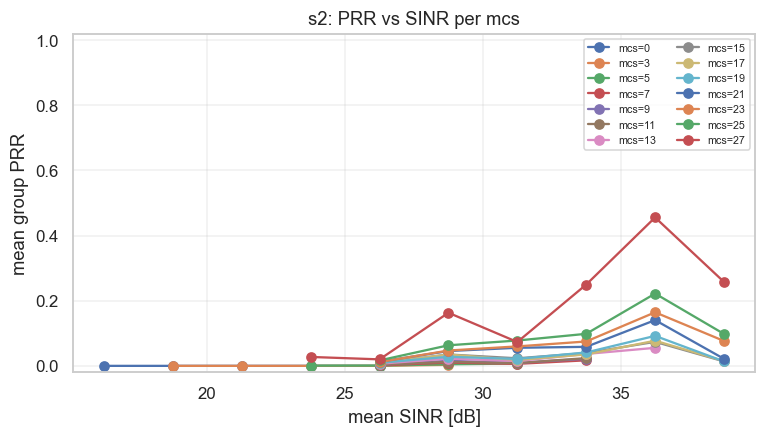

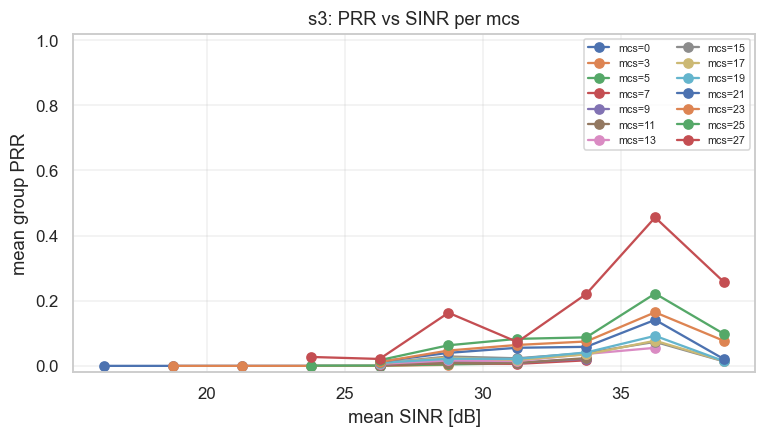

In [12]:
def sinr_curves(df, scen, axis="mcs"):
    sub = df[(df["scen"] == scen) & df["sinr_mean_db"].notna()
             & df["prr_group"].notna()].copy()
    if sub.empty:
        return
    sub["sinr_bin"] = pd.cut(sub["sinr_mean_db"],
                             bins=np.arange(-10, 41, 2.5))
    g = (sub.groupby(["sinr_bin", axis], observed=True)["prr_group"]
            .mean().reset_index())
    g["sinr_mid"] = g["sinr_bin"].apply(lambda b: b.mid).astype(float)
    fig, ax = plt.subplots(figsize=(8, 4))
    for v, gi in g.groupby(axis):
        ax.plot(gi["sinr_mid"], gi["prr_group"], "o-", label=f"{axis}={v}")
    ax.set_xlabel("mean SINR [dB]")
    ax.set_ylabel("mean group PRR")
    ax.set_title(f"{scen}: PRR vs SINR per {axis}")
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, ncol=2)
    plt.show()

for s in ("s1", "s2", "s3"):
    sinr_curves(df, s, "mcs")

## 9. Seed-level dispersion at the optimum

How noisy is the per-cond optimum across seeds?

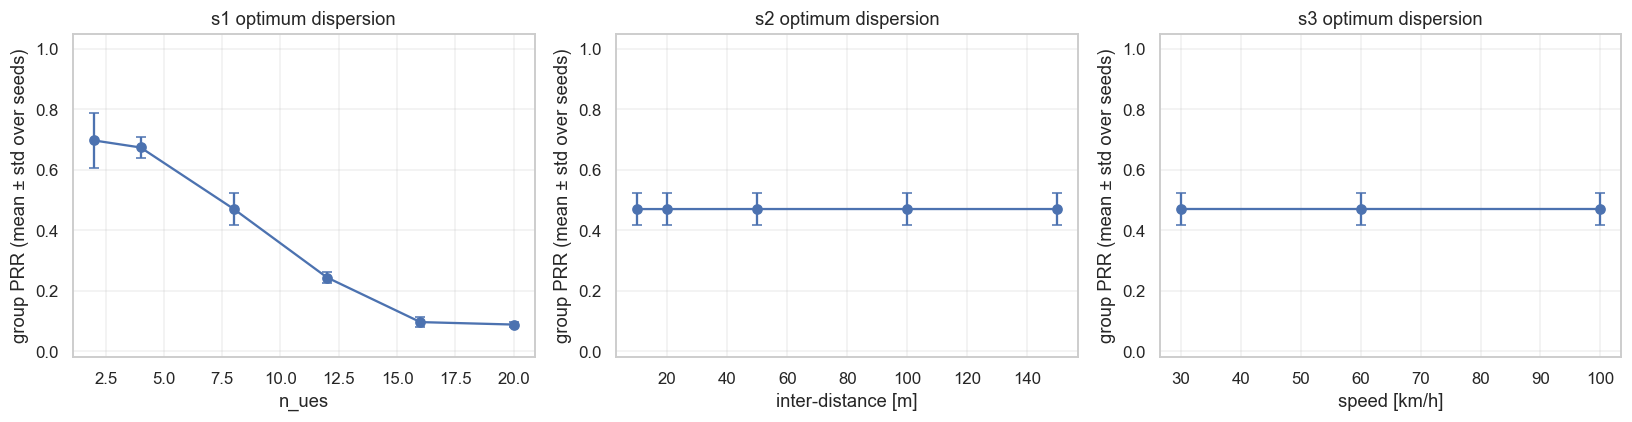

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, scen in zip(axes, ("s1", "s2", "s3")):
    res = optimal_table(agg, scen)
    if res is None:
        continue
    opt, _, _ = res
    ax.errorbar(opt["scen_var"], opt["prr_group_mean"],
                yerr=opt["prr_group_std"], fmt="o-", capsize=3)
    ax.set_xlabel(SCEN_VAR_LABEL[scen])
    ax.set_ylabel("group PRR (mean ± std over seeds)")
    ax.set_title(f"{scen} optimum dispersion")
    ax.set_ylim(-0.02, 1.05)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Per-flow fairness gap

`min(prr_*) / max(prr_*)` across the three flows, per run, vs scenario var.

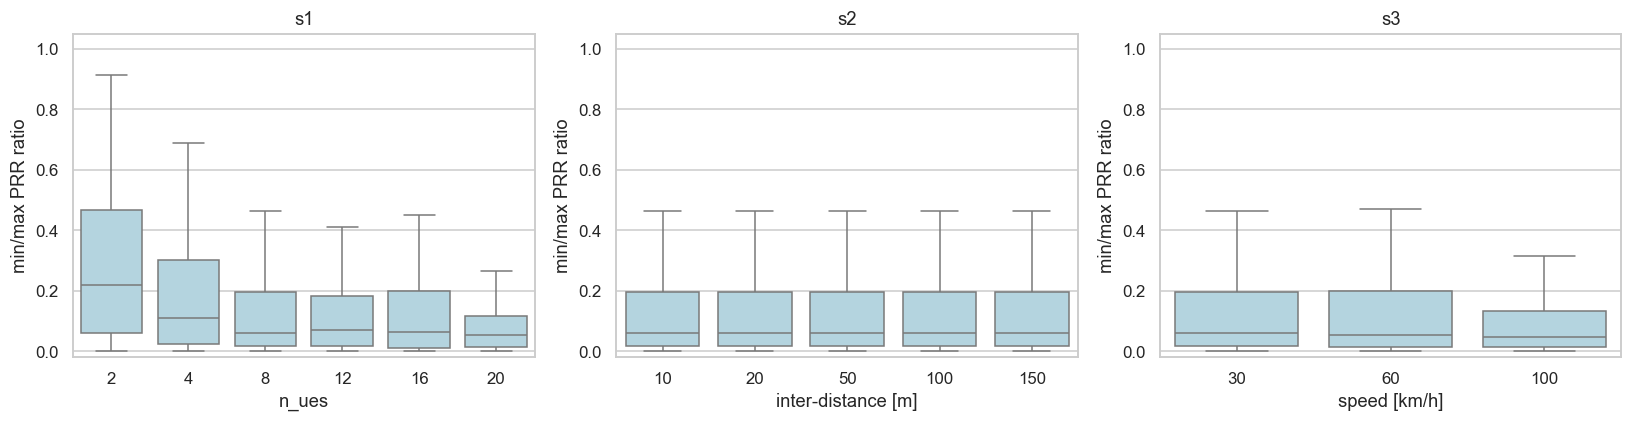

In [14]:
df["fair"] = df[["prr_cam", "prr_vid", "prr_bg"]].min(axis=1) / \
             df[["prr_cam", "prr_vid", "prr_bg"]].max(axis=1).replace(0, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, scen in zip(axes, ("s1", "s2", "s3")):
    sub = df[df["scen"] == scen]
    sns.boxplot(data=sub, x="scen_var", y="fair", ax=ax,
                showfliers=False, color="lightblue")
    ax.set_xlabel(SCEN_VAR_LABEL[scen])
    ax.set_ylabel("min/max PRR ratio")
    ax.set_title(f"{scen}")
    ax.set_ylim(-0.02, 1.05)
plt.tight_layout()
plt.show()

## 11. Goodput proxy

`prr_group * coarse_rate(μ, W, MCS)` at the per-cond optimum. The coarse
rate is a linear-in-MCS proxy (higher MCS → higher bits/symbol) that lets
us pick the *highest-throughput* config rather than just the highest-PRR.

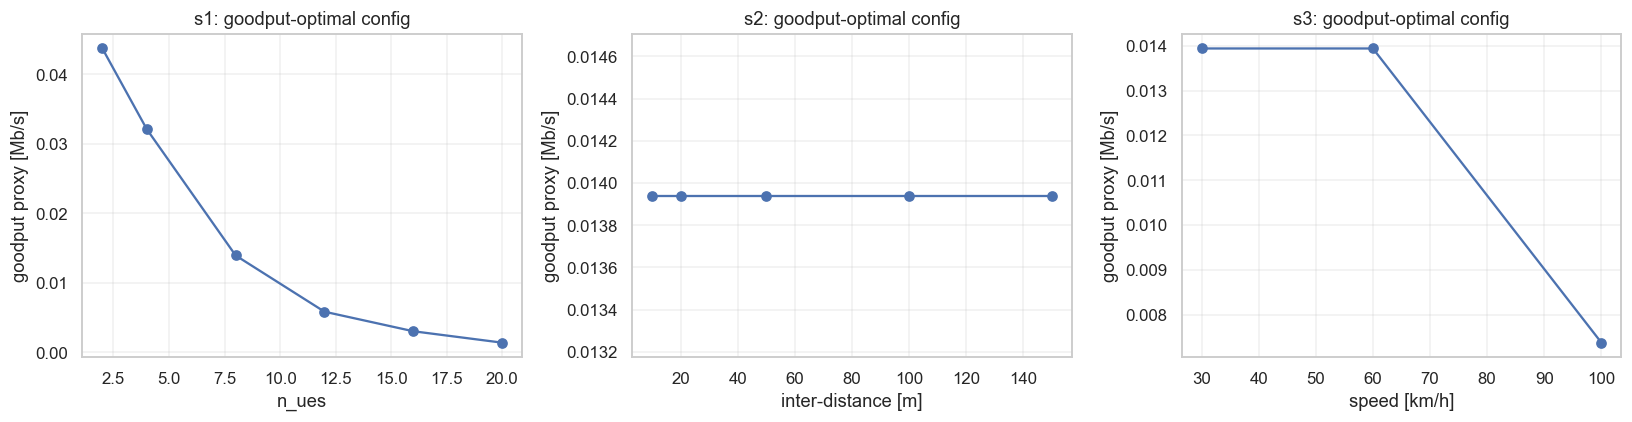

In [15]:
def coarse_rate(mu, w, mcs):
    # 12 sc/RB × 14 sym/slot × W RBs × 2^μ slots/ms × ~(mcs+1)/30 bits/sym
    return 12 * 14 * w * (2 ** mu) * (mcs + 1) / 30

agg["rate"] = agg.apply(lambda r: coarse_rate(r["mu"], r["w"], r["mcs"]), axis=1)
agg["goodput"] = agg["prr_group_mean"] * agg["rate"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, scen in zip(axes, ("s1", "s2", "s3")):
    sub = agg[(agg["scen"] == scen) & agg["goodput"].notna()]
    if sub.empty:
        continue
    idx = sub.groupby(["scen_var", "cond"])["goodput"].idxmax()
    opt = sub.loc[idx].sort_values("scen_var")
    ax.plot(opt["scen_var"], opt["goodput"]/1e6, "o-")
    ax.set_xlabel(SCEN_VAR_LABEL[scen])
    ax.set_ylabel("goodput proxy [Mb/s]")
    ax.set_title(f"{scen}: goodput-optimal config")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. (s1) Best MCS surface — PRR ≥ 0.9 frontier

Where in the (n_ues, distance) plane can each MCS still deliver ≥ 90% PRR?

In [16]:
sub = prr_pair[(prr_pair["mu"] == 1) & (prr_pair["w"] == 100) &
               (prr_pair["flow"] == "cam")]
g = (sub.groupby(["n_ues", "distance_m", "mcs"])["prr_pair"]
        .mean().reset_index())
viable = g[g["prr_pair"] >= 0.9]
if viable.empty:
    print("no (n_ues, dist, mcs) combo reaches PRR ≥ 0.9")
else:
    pv = (viable.groupby(["n_ues", "distance_m"])["mcs"]
                .max().unstack("distance_m"))
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(pv, annot=True, fmt=".0f", cmap="magma", ax=ax,
                cbar_kws={"label": "max MCS with PRR ≥ 0.9"})
    ax.set_title("s1 cam μ=1 W=100 — highest viable MCS in (n_ues, distance)")
    plt.show()

no (n_ues, dist, mcs) combo reaches PRR ≥ 0.9


---
### Notes / next steps
- To extend §4–§5 with more seeds / other flows, rerun
  `per_rx_prr.py` and overwrite `tmp/per_rx_s1.csv`.
- To run §4–§5 against the remote machine's data, copy the helper and
  `scratch_overlay/adaptive-phy-eval/sumo` to the remote, run the script,
  then copy `per_rx_s1{,.pair}.csv` back into `tmp/`.